<a href="https://colab.research.google.com/github/balavardhansai/DSIP/blob/main/Histogramdsip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

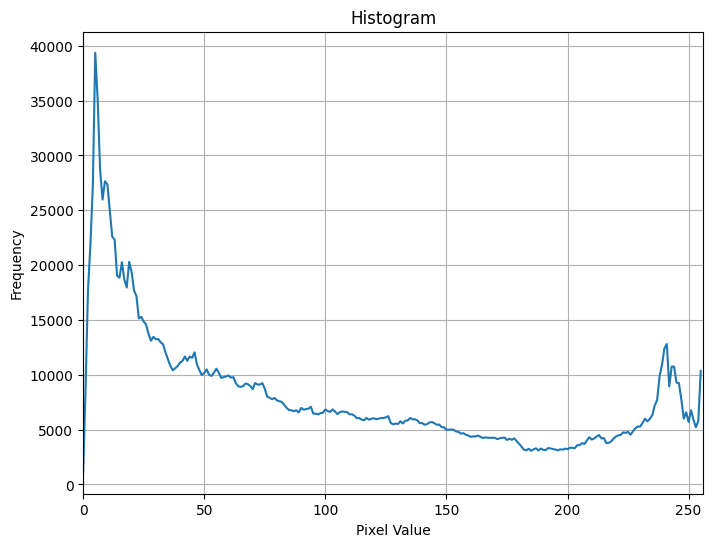

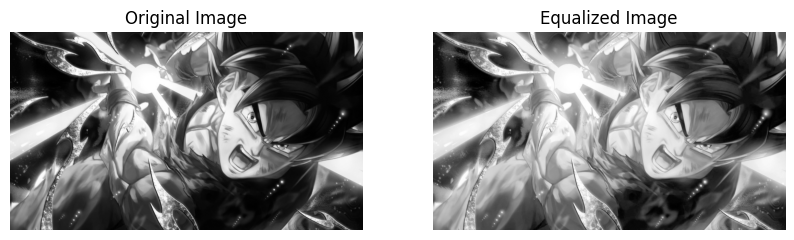

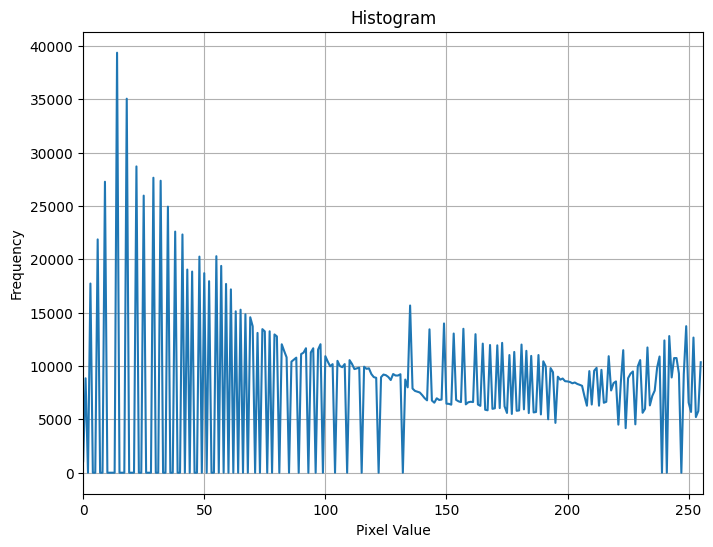

<Figure size 640x480 with 0 Axes>

In [4]:
import cv2
import matplotlib.pyplot as plt
image_path = '/content/go.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
histogram = cv2.calcHist([image], [0], None, [256], [0, 256])
plt.figure(figsize=(8, 6))
plt.title('Histogram')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.plot(histogram)
plt.xlim([0, 256])
plt.grid(True)
plt.show()
equalized_image = cv2.equalizeHist(image)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('Equalized Image')
plt.imshow(equalized_image, cmap='gray')
plt.axis('off')
histogram = cv2.calcHist([equalized_image], [0], None, [256], [0, 256])
plt.figure(figsize=(8, 6))
plt.title('Histogram')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.plot(histogram)
plt.xlim([0, 256])
plt.grid(True)
plt.show()
plt.tight_layout()
plt.show()

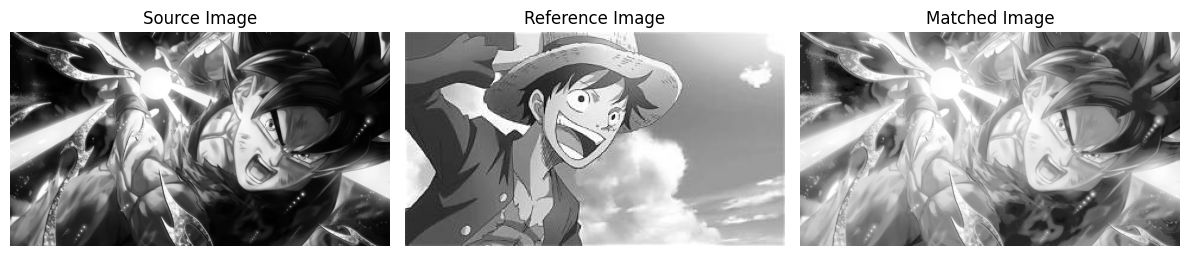

In [5]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
source_path = '/content/go.jpg'
reference_path = '/content/li.jpg'
source_image = cv2.imread(source_path, cv2.IMREAD_GRAYSCALE)
reference_image = cv2.imread(reference_path, cv2.IMREAD_GRAYSCALE)
if source_image is None:
    print(f"Error: Could not load source image from {source_path}. Please ensure the file exists and the path is correct.")
elif reference_image is None:
    print(f"Error: Could not load reference image from {reference_path}. Please ensure the file exists and the path is correct.")
else:
    source_hist = cv2.calcHist([source_image], [0], None, [256], [0, 256])
    reference_hist = cv2.calcHist([reference_image], [0], None, [256], [0, 256])
    source_hist /= source_hist.sum()
    reference_hist /= reference_hist.sum()
    source_cdf = source_hist.cumsum()
    reference_cdf = reference_hist.cumsum()
    mapping = np.interp(source_cdf, reference_cdf, np.arange(256))
    matched_image = mapping[source_image]
    matched_image = matched_image.astype(np.uint8)
    plt.figure(figsize=(12, 6))
    plt.subplot(131)
    plt.title('Source Image')
    plt.imshow(source_image, cmap='gray')
    plt.axis('off')
    plt.subplot(132)
    plt.title('Reference Image')
    plt.imshow(reference_image, cmap='gray')
    plt.axis('off')
    plt.subplot(133)
    plt.title('Matched Image')
    plt.imshow(matched_image, cmap='gray')
    plt.axis('off')
    plt.tight_layout()
    plt.show()